**ESPAÑA - M**

FECHA:xxxx

ID:xxxxxxxx

**FASE 0 : IMPORTACION Y PREPARACIÓN DE DATOS**

Primero entrar en google drive -> permite que el colab pueda acceder a los archivos que tengo guardados.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


as librerias voy a necesitar: las pandas para los dataframe las de numpy para las operaciones numericas display es para mostrar las tablas y los resultados

In [ ]:
#librerias
import pandas as pd
import numpy as np
from IPython.display import display


Nuevas librerías para poder hacer el word automático

necisto instar la libreria

In [ ]:
!pip install python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 14.7 MB/s eta 0:00:00


Para preparar los archivos , word e imagenes para trabajar con las rutas , carpetas etc -> import os con el bloque docx -> para añadir las imagenes, controlar los tamaños + colocar /alinear los textos

In [ ]:
#Gestion archivos
import os

#Generación  informe word
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_PARAGRAPH_ALIGNMENT

#IMAGENES
from PIL import Image

  **CAMBIAR CADA PARTIDO!!!!!**

In [ ]:
# Ruta del archivo
ruta_csv = "/content/drive/MyDrive/FIBA_PlayByPlay/pbp_131881.csv"

pd.read -> coger el csv y convertirlo en una tabla con la que pueda trabajar print(df.shape) -> ¿cuantas filas y columnas tengo? display miro lo que he cargado

In [ ]:
# Leer el CSV
df = pd.read_csv(ruta_csv, encoding="utf-8-sig")

# Primer vistazo a los datos
print(df.shape)
display(df.head())

(573, 24)


,Time,GT,SC,SA,SB,AC,Action,ActionOris,SU,Z1,...,C2,SX,SY,Id,PId,SP,ST,STQ,SortOrder,Quarter
0,10:00,1785766299000,0,0,0,STARTG,Start of game,Start of game,NaN,NaN,...,NaN,0,0,1,NaN,0,0,0,1000,Q1
1,10:00,1785766299000,0,0,0,STARTP,Start of period,Start of period,NaN,NaN,...,NaN,0,0,2,NaN,0,0,0,2000,Q1
2,10:00,1785766299000,0,0,0,JS,jump ball situation; throw-in,Alternating possession gained,NaN,NaN,...,NaN,0,0,4,NaN,0,0,0,4000,Q1
3,9:59,1785766300000,0,0,0,JB,jump ball won,Jump ball won,+,NaN,...,NaN,0,0,5,4.0,0,0,0,4001,Q1
4,9:59,1785766300000,0,0,0,JB,jump ball lost,Jump ball lost,-,NaN,...,NaN,0,0,6,4.0,0,0,0,4002,Q1


necesito ver las columnas que tengo ahora quiero saber que hay en cada columna y lo más importante, de qué tipo son? df.info para saber si se interpreta como numero o como texto df.isna() .sum() cuenta cuantos valores vacios Nan hay en cada columna

In [ ]:
# Ver  columnas
print(df.columns)

# Información general
df.info()

# Valores vacíos
df.isna().sum()

Index(['Time', 'GT', 'SC', 'SA', 'SB', 'AC', 'Action', 'ActionOris', 'SU',
       'Z1', 'Z2', 'Z3', 'T1', 'C1', 'C2', 'SX', 'SY', 'Id', 'PId', 'SP', 'ST',
       'STQ', 'SortOrder', 'Quarter'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 573 entries, 0 to 572
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time        573 non-null    object 
 1   GT          573 non-null    int64  
 2   SC          573 non-null    int64  
 3   SA          573 non-null    int64  
 4   SB          573 non-null    int64  
 5   AC          573 non-null    object 
 6   Action      573 non-null    object 
 7   ActionOris  573 non-null    object 
 8   SU          289 non-null    object 
 9   Z1          321 non-null    object 
 10  Z2          115 non-null    object 
 11  Z3          131 non-null    object 
 12  T1          562 non-null    object 
 13  C1          545 non-null    object 
 14  C2          0 non-

,0
Time,0
GT,0
SC,0
SA,0
SB,0
AC,0
Action,0
ActionOris,0
SU,284
Z1,252


Antes de empezar voy a conocer mejor el archivo (preparación de datos) , luego limpiaré datos

Quiero ver los valores que tiene cada columna

In [ ]:
# Valores únicos de cada columna

for columna in df.columns:
    print(f"\n--- {columna} ---")
    print(df[columna].dropna().unique()[:10])


--- Time ---
['10:00' '9:59' '9:54' '9:52' '9:50' '9:48' '9:27' '9:17' '9:11' '8:53']

--- GT ---
[1785766299000 1785766300000 1785766305000 1785766307000 1785766309000
 1785766311000 1785766335000 1785766370000 1785766378000 1785766427000]

--- SC ---
[0]

--- SA ---
[ 0  3  4  5  7  8  9 10 11 13]

--- SB ---
[ 0  3  4  5  7  9 10 11 12 14]

--- AC ---
['STARTG' 'STARTP' 'JS' 'JB' 'P2' 'REB' 'P3' 'FOUL' 'RFOUL' 'ASS']

--- Action ---
['Start of game' 'Start of period' 'jump ball situation; throw-in'
 'jump ball won' 'jump ball lost'
 '2PtsFG under the basket, driving layup missed' 'offensive rebound'
 '3pt jump shot missed' 'defensive rebound' 'Personal foul']

--- ActionOris ---
['Start of game' 'Start of period' 'Alternating possession gained'
 'Jump ball won' 'Jump ball lost'
 '2PtsFG under the basket, driving layup missed' 'Offensive rebound'
 '3PtsFG outside center, jump shot missed' 'Defensive rebound'
 'Personal foul']

--- SU ---
['+' '-']

--- Z1 ---
['PUB' 'O' 'C' 'D' 'P' 

Me voy a centrar en las acciones , porque son las que me van a permitir reconstruir las posesiones

In [ ]:
#acciones  partido

df["Action"].value_counts()

,count
Action,
Substitution out,65
Substitution in,65
defensive rebound,42
foul drawn,35
made the assist,33
...,...
"2PtsFG inside left, points after turnover, jump shot made",1
2pt floating jump shot missed,1
blocked the shot,1


tengo que mirar solo la columna AC que es donde tengo los codigos de accion

y luego cuento cuántas veces aparace cada codigo y los ordeno

In [ ]:
#codigos de accion

df["AC"].value_counts()

,count
AC,
SUBST,130
P2,76
REB,73
TO,47
P3,42
FT,39
RFOUL,35
FOUL,35
ASS,33


P2 → tiros de 2.
P3 → tiros de 3.
FT → tiros libres.
REB → rebotes.
TO → pérdidas.
ASS → asistencias.
FOUL → faltas.
RFOUL → faltas recibidas.
ST → robos.
BS → tapones.
SUBST → cambios.
TIMO → tiempos muertos.

Y además aparecen los eventos del partido:


STARTG → inicio del partido.
STARTP → inicio del cuarto.
ENDP → final del cuarto.
ENDG → final del partido

ahora voy a ordenar todas las acciones . Saber cuando empieza y termina una posesion

¿empieza cada cuarto con startp?
aparece el salto inicial (jumpb)? termina el cuarto en endp?


In [ ]:
#ordenar acciones

df= df.sort_values("SortOrder").reset_index(drop=True)

necesito ver si el playbyplay está siguiendo el partido como realmente ha ocurrido.

para seguir la secuencia: empieza el cuarto, salto inicial, un equipo gana el salto, llega un triple fallado, rebote ofensivo, ...etc

-> reconstruyo la historia del partido -> + adelante voy a traajar con las posesiones , sustituciones y jugadoras en pista. **NECESITO LAS ACCIONES EN ORDEN. IMPORTANTEEEEEEEEEE!!!!!!**

In [ ]:
# Comprobar el orden de las acciones
display(df[["Quarter", "Time", "AC", "Action", "T1"]].head(30))

,Quarter,Time,AC,Action,T1
0,Q1,10:00,STARTG,Start of game,NaN
1,Q1,10:00,STARTP,Start of period,NaN
2,Q1,10:00,JS,jump ball situation; throw-in,NaN
3,Q1,9:59,JB,jump ball won,T_138
4,Q1,9:59,JB,jump ball lost,T_8310
5,Q1,9:54,P2,"2PtsFG under the basket, driving layup missed",T_138
6,Q1,9:52,REB,offensive rebound,T_138
7,Q1,9:50,P3,3pt jump shot missed,T_138
8,Q1,9:48,REB,defensive rebound,T_8310
9,Q1,9:27,FOUL,Personal foul,T_138


¿CÓMO TERMINA EL PARTIDO?

.tail es para ver las ultimas filas

ojo! si luego voy a reconstruir posesiones, parejas, ... necisto estar segura de que no me falta un trozo del partido

In [ ]:
# Comprobar el final del partido
display(df[["Quarter", "Time", "AC", "Action", "T1"]].tail(30))

,Quarter,Time,AC,Action,T1
543,Q4,2:08,ASS,made the assist,T_138
544,Q4,1:52,P2,"2PtsFG under the basket, driving layup missed",T_8310
545,Q4,1:50,REB,defensive rebound,T_138
546,Q4,1:49,TO,turnover; bad pass,T_138
547,Q4,1:49,ST,steal,T_8310
548,Q4,1:40,TO,turnover; ball handling,T_8310
549,Q4,1:40,ST,steal,T_138
550,Q4,1:27,P2,"2PtsFG under the basket, points after turnover...",T_138
551,Q4,1:27,ASS,made the assist,T_138
552,Q4,1:27,SUBST,Substitution out,T_8310


RECONSTRUCCION DE POSESIONES

Una posesión comienza cuando un equipo obtiene el control del balón.

Una posesión termina cuando el equipo pierde el control del balón o finalizar el ataque

una canasta convertida termina siempre la posesion? si

un rebote defensivo inicia una nueva posesión? si

un rebote ofensivo mantiene la misma posesión? si

una perdida termina la posesión? si

un tiro fallado sin rebote todavia no termina la posesión? si, hasta que se sepa quién captura el rebote.

**Una posesión termina cuando:**

Canasta convertida.
Rebote defensivo del equipo rival.
Pérdida de balón.
Final del cuarto.
Final del partido.

**La posesión continúa cuando:**

Rebote ofensivo.
Pase.
Asistencia.
Falta recibida (si el equipo mantiene la posesión).
Tiros libres que forman parte de la misma posesión.


In [ ]:
#necesito ver que acciones pueden terminar una posesion
#saco una lista de los codigos de accion junto con su descripcion

#codigo de accion
df[["AC","Action"]].drop_duplicates().sort_values("AC")

,AC,Action
12,ASS,made the assist
557,BS,blocked the shot
60,CFOUL,Technical foul coach
572,ENDG,End of game
150,ENDP,End of period
...,...,...
38,TO,turnover; ball handling
17,TO,turnover; bad pass
192,TREB,team offensive rebound
94,TREB,team defensive rebound


¿qué acciones hacen que cambie el equipo que tiene el balón?

Investigo el pbp

quiero saber solo las perdidas de balon -> TO turnover

Asi voy a poder ver que tipo de perdida ha sido, que equipo la ha hecho

Es importante empezar por aqui porque -> una perdida normalmente supone el final de la posesion de un equipo y el comienzo de la del rival.

ACCION CLAVE!!!

In [ ]:
# Pérdidas de balón

display(df[df["AC"] == "TO"][["Quarter", "Time", "AC", "Action", "T1"]].head(15))

,Quarter,Time,AC,Action,T1
17,Q1,8:43,TO,turnover; bad pass,T_8310
27,Q1,8:20,TO,turnover; bad pass,T_138
38,Q1,7:31,TO,turnover; ball handling,T_138
41,Q1,7:22,TO,turnover; ball handling,T_8310
68,Q1,5:38,TO,turnover; bad pass,T_138
71,Q1,5:20,TO,turnover; bad pass,T_8310
75,Q1,4:48,TO,turnover; bad pass,T_8310
86,Q1,4:17,TO,turnover; ball handling,T_8310
91,Q1,3:51,TO,turnover; ball handling,T_8310
97,Q1,3:28,TO,turnover; double dribble,T_8310


después de un tiro fallado ¿quien se queda con el balon? tengo que mirar los rebotes.

¿cuando ocurre, que tipo de rebote es y que equipo lo consigue???

In [ ]:
# Rebotes

display(df[df["AC"] == "REB"][["Quarter", "Time", "AC", "Action", "T1"]].head(15))

,Quarter,Time,AC,Action,T1
6,Q1,9:52,REB,offensive rebound,T_138
8,Q1,9:48,REB,defensive rebound,T_8310
20,Q1,8:38,REB,offensive rebound,T_138
26,Q1,8:24,REB,defensive rebound,T_138
34,Q1,7:58,REB,offensive rebound,T_138
37,Q1,7:38,REB,defensive rebound,T_138
48,Q1,6:51,REB,defensive rebound,T_138
58,Q1,6:14,REB,defensive rebound,T_138
67,Q1,5:39,REB,defensive rebound,T_138
99,Q1,3:12,REB,offensive rebound,T_138


tengo que ver el final o la continuacion de una posesion . Miro el tiro de 2 .

ojo! no todos los tiros de 2 son iguales .

-si el tiro entra (made): termina la posesion de ese equipo y el balon pasa al rival
-si el tiro se falla (missed) todavia no se ha terminado la posesion
...

In [ ]:
# Tiros de 2

display(df[df["AC"] == "P2"][["Quarter", "Time", "AC", "Action", "T1"]].head(15))

,Quarter,Time,AC,Action,T1
5,Q1,9:54,P2,"2PtsFG under the basket, driving layup missed",T_138
19,Q1,8:39,P2,"2PtsFG under the basket, points after turnover...",T_138
25,Q1,8:26,P2,"2PtsFG under the basket, driving layup missed",T_8310
35,Q1,7:49,P2,2pt driving layup made,T_138
47,Q1,6:54,P2,2pt pullup jump shot missed,T_8310
57,Q1,6:16,P2,2pt jump shot missed,T_8310
59,Q1,6:02,P2,2pt jump shot made,T_138
73,Q1,5:04,P2,"2PtsFG inside center, points after turnover, j...",T_138
77,Q1,4:44,P2,"2PtsFG inside paint, points from fastbreak + a...",T_138
88,Q1,4:14,P2,"2PtsFG inside paint, points from fastbreak + a...",T_138


necesito saber qué equipo es España , si T_618 o T_138.

miro el resultado final .

In [ ]:
#marcador final
df[["SA","SB"]].tail()


,SA,SB
568,87,37
569,87,38
570,87,39
571,87,39
572,87,39


87-39 (ya sé que España es el de 87 SA es España

Voy a ver las primeras 30 acciones del partido

In [ ]:
#primeras acciones del partido
display(df.loc[0:30, ["Quarter", "Time", "AC", "Action", "T1", "SA","SB"]])

,Quarter,Time,AC,Action,T1,SA,SB
0,Q1,10:00,STARTG,Start of game,NaN,0,0
1,Q1,10:00,STARTP,Start of period,NaN,0,0
2,Q1,10:00,JS,jump ball situation; throw-in,NaN,0,0
3,Q1,9:59,JB,jump ball won,T_138,0,0
4,Q1,9:59,JB,jump ball lost,T_8310,0,0
5,Q1,9:54,P2,"2PtsFG under the basket, driving layup missed",T_138,0,0
6,Q1,9:52,REB,offensive rebound,T_138,0,0
7,Q1,9:50,P3,3pt jump shot missed,T_138,0,0
8,Q1,9:48,REB,defensive rebound,T_8310,0,0
9,Q1,9:27,FOUL,Personal foul,T_138,0,0


Los tiros libres suelen dar problemas a la hora de construir posesiones. Tengo que ver como lo registra el pbp .

si distingue entre tiro anotado y fallado

si aparecen varios tiros libres seguidos

qué ocurre justo después (rebote, saque, etc)

In [ ]:
#tiros libres

display(df[df["AC"]== "FT"][["Quarter", "Time", "AC", "Action", "T1"]].head(20))

,Quarter,Time,AC,Action,T1
23,Q1,8:38,FT,1st of 2 free throws made,T_138
24,Q1,8:38,FT,2nd of 2 free throws made,T_138
31,Q1,8:17,FT,Free throw made 1 of 2,T_8310
32,Q1,8:17,FT,Free throw made 2 of 2,T_8310
45,Q1,7:20,FT,Free throw made 1 of 2,T_138
46,Q1,7:20,FT,Free throw made 2 of 2,T_138
55,Q1,6:41,FT,1st of 2 free throws made,T_138
56,Q1,6:41,FT,2nd of 2 free throws made,T_138
61,Q1,5:55,FT,1st free throw missed,T_138
124,Q1,1:16,FT,1st of 2 free throws made,T_8310


El archivo distingue perfectamente entre el primer tiro libre y el segundo tiro libre.

Un tiro libre no siempre termina en una posesión.

Ejemplo: si es el primer tiro libre, la posesión continúa porque queda otro lanzamiento. Si es el segundo, dependerá de si entra o falla y de quién capture el rebote si falla.

Creo la columna fin_posesion , que tendrá dos valores 🇰

true , esta acción termina en posesión

false, la acción no la termina

**FASE 1 : CRONSTRUCCIÓN DE LAS POSESIONES. CREAR FIN_POSESION**

In [ ]:
#crear la columna Fin_Posesion

df["Fin_Posesion"]= False

Marcar las pérdidas, que ya sé con seguridad que terminan en una posesión.

Busca todas las filas donde AC es TO y cambia Fin_Posesion a True

In [ ]:
#marcar las pérdidas

df.loc[df["AC"]=="TO","Fin_Posesion"]=True

el pbp original no me dice directamente aqui termina la posesion , soy yo quien está creando esa informacion a partir de las acciones.

TO-> fin de posesion-> true

es como un control de seguridad

In [ ]:
#comprobar que funciona

display(df[df["AC"]== "TO"][["Quarter", "Time", "AC", "Action", "Fin_Posesion"]].head(10))

,Quarter,Time,AC,Action,Fin_Posesion
17,Q1,8:43,TO,turnover; bad pass,True
27,Q1,8:20,TO,turnover; bad pass,True
38,Q1,7:31,TO,turnover; ball handling,True
41,Q1,7:22,TO,turnover; ball handling,True
68,Q1,5:38,TO,turnover; bad pass,True
71,Q1,5:20,TO,turnover; bad pass,True
75,Q1,4:48,TO,turnover; bad pass,True
86,Q1,4:17,TO,turnover; ball handling,True
91,Q1,3:51,TO,turnover; ball handling,True
97,Q1,3:28,TO,turnover; double dribble,True


Igual que con pérdidas, ahora tengo que ir una a una viendo todas las reglas de posesión: pérdidas, canastas convertidas, rebotes defensivos, final de cuarto, final de partido, tiros libres.

si hay canasta -> se acabó la posesion

Ya tengo controladas las perdidas , ahora voy con otra: si un equipo mete una canasta de 2 o de 3, su posesion termina y el balon pasa al rival

EStoy buscando p2 y p3, pero solo quiero aquellos que sean made -> los que realmente han entrado

con & estoy diciendo que se tienen que cumplir las dos a la vez

In [ ]:
# Marcar canastas convertidas

df.loc[
    (df["AC"].isin(["P2", "P3"])) &
    (df["Action"].str.contains("made", case=False, na=False)),
    "Fin_Posesion"
] = True

# Comprobar canastas convertidas

display(
    df[
        (df["AC"].isin(["P2", "P3"])) &
        (df["Action"].str.contains("made", case=False, na=False))
    ][["Quarter", "Time", "AC", "Action", "Fin_Posesion"]].head(10)
)

,Quarter,Time,AC,Action,Fin_Posesion
11,Q1,9:17,P3,3pt jump shot made,True
15,Q1,8:53,P3,3pt jump shot made,True
35,Q1,7:49,P2,2pt driving layup made,True
59,Q1,6:02,P2,2pt jump shot made,True
73,Q1,5:04,P2,"2PtsFG inside center, points after turnover, j...",True
77,Q1,4:44,P2,"2PtsFG inside paint, points from fastbreak + a...",True
88,Q1,4:14,P2,"2PtsFG inside paint, points from fastbreak + a...",True
100,Q1,3:06,P2,layup made,True
102,Q1,2:47,P2,layup made,True
106,Q1,2:26,P2,"2PtsFG under the basket, driving layup made",True


ahora veo : rebote ofensivo = cambio de posesion

si el rival ha tirado , ha fallado y yo cojo el rebote -> el ataque se acaba

primero se busca las acciones que fiba identifica como rebote , peros solo me quedo con las acciones que pongan defensive rebound


importante! el rebote ofensivo NO lo marco como final de posesion. Si fallo y mi propio equipo captura el rebote -> no se ha terminado , se sigue atacando .

El rebote ofensivo confirma que el equipo que estaba atacando -> ha perdido definitivamente la oportunidad de continuar con el ataque -> balón pasaria al otro equipo.

In [ ]:
# Marcar rebotes defensivos

df.loc[
    (df["AC"].isin(["REB", "TREB"])) &
    (df["Action"].str.contains("defensive rebound", case=False, na=False)),
    "Fin_Posesion"
] = True

# Comprobar rebotes defensivos

display(
    df[
        (df["AC"].isin(["REB", "TREB"])) &
        (df["Action"].str.contains("defensive rebound", case=False, na=False))
    ][["Quarter", "Time", "AC", "Action", "Fin_Posesion"]].head(10)
)


,Quarter,Time,AC,Action,Fin_Posesion
8,Q1,9:48,REB,defensive rebound,True
26,Q1,8:24,REB,defensive rebound,True
37,Q1,7:38,REB,defensive rebound,True
48,Q1,6:51,REB,defensive rebound,True
58,Q1,6:14,REB,defensive rebound,True
67,Q1,5:39,REB,defensive rebound,True
94,Q1,3:46,TREB,team defensive rebound,True
105,Q1,2:33,REB,defensive rebound,True
117,Q1,1:50,REB,defensive rebound,True
126,Q1,1:16,REB,defensive rebound,True


El rebote ofensivo NO termina en posesión asi que debe de aparecer como false.

In [ ]:
# Comprobar rebotes ofensivos

display(
    df[
        (df["AC"].isin(["REB", "TREB"])) &
        (df["Action"].str.contains("offensive rebound", case=False, na=False))
    ][["Quarter", "Time", "AC", "Action", "Fin_Posesion"]].head(10)
)

,Quarter,Time,AC,Action,Fin_Posesion
6,Q1,9:52,REB,offensive rebound,False
20,Q1,8:38,REB,offensive rebound,False
34,Q1,7:58,REB,offensive rebound,False
99,Q1,3:12,REB,offensive rebound,False
132,Q1,0:42,REB,offensive rebound,False
141,Q1,0:12,REB,offensive rebound,False
143,Q1,0:10,REB,offensive rebound,False
192,Q2,6:57,TREB,team offensive rebound,False
246,Q2,2:31,REB,offensive rebound,False
255,Q2,1:42,REB,offensive rebound,False


**Final de cuarto y final de partido**


e acaba el cuarto -> se acaba la posesion

aunque no haya habido perdida, canasta o rebote defensivo, si el reloj llega a 00:00 , esa posesion -> se termina si o si!

In [ ]:
# Marcar final de cuarto

df.loc[df["AC"] == "ENDP", "Fin_Posesion"] = True

# Comprobar final de cuarto

display(
    df[df["AC"] == "ENDP"][["Quarter", "Time", "AC", "Action", "Fin_Posesion"]]
)


,Quarter,Time,AC,Action,Fin_Posesion
150,Q1,0:00,ENDP,End of period,True
275,Q2,0:00,ENDP,End of period,True
442,Q3,0:00,ENDP,End of period,True
571,Q4,0:00,ENDP,End of period,True


In [ ]:
# Marcar final de partido

df.loc[df["AC"] == "ENDG", "Fin_Posesion"] = True


In [ ]:
# Comprobar final de partido

display(
    df[df["AC"] == "ENDG"][["Quarter", "Time", "AC", "Action", "Fin_Posesion"]]
)

,Quarter,Time,AC,Action,Fin_Posesion
572,Q4,0:00,ENDG,End of game,True


**Numerar las posesiones**

Como False vale 0 y True vale 1 , va contando cuántas posesiones han terminado.

Cada vez que aparece un True, el contador aumenta y comienza una nueva posesión.

ahora voy leyendo el partido, mientras no termine la posesion se mantiene el mismo numero. Cuando se encuentre un final , se aumenta el contador y empieza la nueva.


En cuanto aparezca la primera con true el contador avanza

AHORA EMPIEZO A CONTRUIR : POSESION 1-> POSESION 1-> ....HASTA UN TRUE -> POSESION 2

In [ ]:
# Numerar las posesiones

df["Posesion"] = df["Fin_Posesion"].cumsum() + 1


In [ ]:
# Comprobar las posesiones

display(
    df[["Quarter", "Time", "AC", "Action", "Fin_Posesion", "Posesion"]].head(20)
)

,Quarter,Time,AC,Action,Fin_Posesion,Posesion
0,Q1,10:00,STARTG,Start of game,False,1
1,Q1,10:00,STARTP,Start of period,False,1
2,Q1,10:00,JS,jump ball situation; throw-in,False,1
3,Q1,9:59,JB,jump ball won,False,1
4,Q1,9:59,JB,jump ball lost,False,1
5,Q1,9:54,P2,"2PtsFG under the basket, driving layup missed",False,1
6,Q1,9:52,REB,offensive rebound,False,1
7,Q1,9:50,P3,3pt jump shot missed,False,1
8,Q1,9:48,REB,defensive rebound,True,2
9,Q1,9:27,FOUL,Personal foul,False,2


Hay un fallo en la acción 2pts fg...layup made true 2 , la canasta debería pertenecer a la posesión 1 , porque es la acción que termina esa posesión. La posesión 2 debería de empezar en la siguiente. Tengo que corregirlo.

Observación: este método numera la canasta, la pérdida o el rebote defensivo como si pertenecieran a la siguiente posesión. Sin embargo, esas acciones son las que finalizan la posesión actual, no las que comienzan la siguiente.

In [ ]:
# Numerar correctamente las posesiones

df["Posesion"] = df["Fin_Posesion"].shift(fill_value=False).cumsum() + 1

# Comprobar las posesiones

display(
    df[["Quarter", "Time", "AC", "Action", "Fin_Posesion", "Posesion"]].head(20)
)


,Quarter,Time,AC,Action,Fin_Posesion,Posesion
0,Q1,10:00,STARTG,Start of game,False,1
1,Q1,10:00,STARTP,Start of period,False,1
2,Q1,10:00,JS,jump ball situation; throw-in,False,1
3,Q1,9:59,JB,jump ball won,False,1
4,Q1,9:59,JB,jump ball lost,False,1
5,Q1,9:54,P2,"2PtsFG under the basket, driving layup missed",False,1
6,Q1,9:52,REB,offensive rebound,False,1
7,Q1,9:50,P3,3pt jump shot missed,False,1
8,Q1,9:48,REB,defensive rebound,True,1
9,Q1,9:27,FOUL,Personal foul,False,2


Se ha utilizado shift() para que el cambio de número de posesión ocurra en la acción siguiente, que es cuando realmente comienza la nueva acción.

**Crear el equipo de la posesión**.

Yo solo quiero analizar España.

In [ ]:
#ver los equipos

print(df["T1"].dropna().unique())

['T_138' 'T_8310']


Ya sé cuál es España. -> T_138

Ahora hago una comprobación. en todas las acciones aparece el equipo que está atacando?

Si la columna T1 representa siempre al equipo que realiza la acción

OJO! ya se quien es españa pero necesito construir correctamente que equipo corresponde a cada posesion completa, no quedarme solo con el t1 de cada fila.

miro quien realiza el tiro

miro quien captura el rebote

miro quien realiza el robo

In [ ]:
# Canastas de 2

display(df[df["AC"] == "P2"][["Action", "T1"]].head(10))

# Rebotes

display(df[df["AC"] == "REB"][["Action", "T1"]].head(10))

# Robos

display(df[df["AC"] == "ST"][["Action", "T1"]].head(10))


,Action,T1
5,"2PtsFG under the basket, driving layup missed",T_138
19,"2PtsFG under the basket, points after turnover...",T_138
25,"2PtsFG under the basket, driving layup missed",T_8310
35,2pt driving layup made,T_138
47,2pt pullup jump shot missed,T_8310
57,2pt jump shot missed,T_8310
59,2pt jump shot made,T_138
73,"2PtsFG inside center, points after turnover, j...",T_138
77,"2PtsFG inside paint, points from fastbreak + a...",T_138
88,"2PtsFG inside paint, points from fastbreak + a...",T_138


,Action,T1
6,offensive rebound,T_138
8,defensive rebound,T_8310
20,offensive rebound,T_138
26,defensive rebound,T_138
34,offensive rebound,T_138
37,defensive rebound,T_138
48,defensive rebound,T_138
58,defensive rebound,T_138
67,defensive rebound,T_138
99,offensive rebound,T_138


,Action,T1
18,steal,T_138
28,steal,T_8310
42,steal,T_138
72,steal,T_138
76,steal,T_138
87,steal,T_138
92,steal,T_138
109,steal,T_8310
134,steal,T_8310
147,steal,T_138


El T1 no indica el equipo que tiene la posesión, sino el equipo que realiza la acción. IMPORTANTE.

la idea: para cada número de posesión (1,2,3...) identificar la primera acción "real" de esa posesión.

El T1 de esa primera acción será el equipo que tiene la posesión.

**Ver la primera acción de cada posesión**

In [ ]:
# Primera acción de cada posesión

primeras = df.groupby("Posesion").first()
display(primeras.head(10))

,Time,GT,SC,SA,SB,AC,Action,ActionOris,SU,Z1,...,SX,SY,Id,PId,SP,ST,STQ,SortOrder,Quarter,Fin_Posesion
Posesion,,,,,,,,,,,,,,,,,,,,,
1,10:00,1785766299000,0,0,0,STARTG,Start of game,Start of game,+,PUB,...,0,0,1,4.0,0,0,0,1000,Q1,False
2,9:27,1785766335000,0,0,0,FOUL,Personal foul,Personal foul,+,P,...,32,69,12,12.0,0,0,0,8000,Q1,False
3,9:17,1785766370000,0,0,3,ASS,made the assist,Assist,+,P,...,0,0,16,15.0,0,0,0,10001,Q1,False
4,8:53,1785766427000,0,3,3,ASS,made the assist,Assist,None,BP,...,0,0,24,23.0,0,0,0,16001,Q1,False
5,8:43,1785766436000,0,3,3,ST,steal,Steal,-,PUB,...,0,0,26,25.0,0,0,0,17001,Q1,False
6,8:20,1785766590000,0,5,3,TO,turnover; bad pass,"Turnover, bad pass",None,BP,...,0,0,43,NaN,0,0,0,31000,Q1,True
7,8:20,1785766590000,0,5,3,ST,steal,Steal,+,P,...,0,0,45,43.0,0,0,0,31001,Q1,False
8,7:41,1785766679000,0,7,5,P3,3pt pullup jump shot missed,"3PtsFG outside left, pullup jump shot missed",-,LL,...,30,115,54,54.0,0,0,0,39000,Q1,False
9,7:31,1785766690000,0,7,5,TO,turnover; ball handling,"Turnover, ball handling",None,LB,...,0,0,57,NaN,0,0,0,41000,Q1,True


no me sirve groupby first, la primera acción de una posesión no siempre es el inicio real del ataque. A veces es una asistencia, un robo, un saque...porque así está registrado en el pbp

No debo asumir que la primera fila de una posesión identifica el equipo atacante

Voy a inspeccionar una posesión completa

In [ ]:
# Ver una posesión completa

display(
    df[df["Posesion"] == 2][
        ["Quarter", "Time", "AC", "Action", "T1", "Fin_Posesion"]
    ]
)


,Quarter,Time,AC,Action,T1,Fin_Posesion
9,Q1,9:27,FOUL,Personal foul,T_138,False
10,Q1,9:27,RFOUL,foul drawn,T_8310,False
11,Q1,9:17,P3,3pt jump shot made,T_8310,True


No tiene sentido como una única posesión. No es un problema de T1 . El problema está en cómo estoy definiendo el final de la posesión.

La asistencia ass aparece después de la canasta, he creado Fin_Posesion = true pero la asistencia pertenece a la misma jugada que la canasta. Por eso, al desplazar con shift() , la asistencia ha pasado a la posesión siguiente.

**CORREGIR : ASS , RFOUL Y ALGUNAS ESTADISTICAS ASOCIADAS AL TIRO.**

CORREGIR: usando PId, que relaciona una acción secundaria con la acción principal.

La asistencia tiene como PId el Id de la canasta.

El robo como PId el Id de la pérdida.

In [ ]:
# Corregir acciones relacionadas

for i in range(len(df) - 1):

    if df.loc[i, "Fin_Posesion"] == True:

        if df.loc[i + 1, "PId"] == df.loc[i, "Id"]:

            df.loc[i, "Fin_Posesion"] = False
            df.loc[i + 1, "Fin_Posesion"] = True

In [ ]:
# Volver a numerar las posesiones

df["Posesion"] = (
    df["Fin_Posesion"]
    .shift(fill_value=False)
    .cumsum()
    + 1
)

In [ ]:
# Comprobar la corrección

display(
    df[
        ["Id", "PId", "Quarter", "Time", "AC",
         "Action", "T1", "Fin_Posesion", "Posesion"]
    ].head(20)
)

,Id,PId,Quarter,Time,AC,Action,T1,Fin_Posesion,Posesion
0,1,NaN,Q1,10:00,STARTG,Start of game,NaN,False,1
1,2,NaN,Q1,10:00,STARTP,Start of period,NaN,False,1
2,4,NaN,Q1,10:00,JS,jump ball situation; throw-in,NaN,False,1
3,5,4.0,Q1,9:59,JB,jump ball won,T_138,False,1
4,6,4.0,Q1,9:59,JB,jump ball lost,T_8310,False,1
5,7,NaN,Q1,9:54,P2,"2PtsFG under the basket, driving layup missed",T_138,False,1
6,8,7.0,Q1,9:52,REB,offensive rebound,T_138,False,1
7,9,NaN,Q1,9:50,P3,3pt jump shot missed,T_138,False,1
8,10,9.0,Q1,9:48,REB,defensive rebound,T_8310,True,1
9,12,NaN,Q1,9:27,FOUL,Personal foul,T_138,False,2


Ahora ocurre:

canasta + asistencia -> misma posesión

pérdida + robo -> misma posesión

la siguiente acción real comenzará una posesión nueva.

Ahora reviso los tiros libres que son los  más complicados.

In [ ]:
# Ver una posesión con tiros libres

display(
    df[df["Posesion"] == 4][
        ["Quarter", "Time", "AC", "Action", "T1", "Fin_Posesion"]
    ]
)

,Quarter,Time,AC,Action,T1,Fin_Posesion
17,Q1,8:43,TO,turnover; bad pass,T_8310,False
18,Q1,8:43,ST,steal,T_138,True


**CREAR LA TABLA DE POSESIONES, CON UNA FILA POR POSESION**

ahora hago resumen -> una fila = una posesion

hasta ahora mi dataframe tiene una fila por accion -> bien para construir el partido

pero necesito una tabla más completa y limpia! cada fila va a representar una posesion completa


cuarto -> dime que cuarto ocurre esta posesion , me quedo con el primer valor porque todas esas acciones deberian de pertenecer al primer cuarto

inicio ¿en que momento el reloj empezó la posesion?

final -> cuando termina

acciones -> cuantas acciones del pbp hubo dentro de esa posesion

.reset_index : una vez hecho el resumen, necesito dejar posesion como una columan normal para tenr una tabla facil con la que seguir.

In [ ]:
# Crear dataset de posesiones

posesiones = df.groupby("Posesion").agg(
    Cuarto=("Quarter", "first"),
    Inicio=("Time", "first"),
    Final=("Time", "last"),
    Acciones=("Action", "count")
).reset_index()


# Comprobar dataset de posesiones

display(posesiones.head(10))


,Posesion,Cuarto,Inicio,Final,Acciones
0,1,Q1,10:00,9:48,9
1,2,Q1,9:27,9:17,4
2,3,Q1,9:11,8:53,4
3,4,Q1,8:43,8:43,2
4,5,Q1,8:39,8:24,8
5,6,Q1,8:20,8:20,2
6,7,Q1,8:17,7:49,7
7,8,Q1,7:41,7:38,2
8,9,Q1,7:31,7:31,1
9,10,Q1,7:31,7:22,4


**AÑADIR EL EQUIPO CON POSESIÓN**

Cada posesión se asigna al equipo que realiza la primera acción de juego de esa posesión.

Esta variable permitirá posteriormente filtrar las posesiones de España y calcular todos los indicadores ofensivos.

In [ ]:
# Equipo que inicia cada posesión

equipo = (
    df.groupby("Posesion")["T1"]
      .first()
      .reset_index(name="Equipo")
)

posesiones = posesiones.merge(equipo, on="Posesion")

#compruebo
display(posesiones.head(10))

,Posesion,Cuarto,Inicio,Final,Acciones,Equipo
0,1,Q1,10:00,9:48,9,T_138
1,2,Q1,9:27,9:17,4,T_138
2,3,Q1,9:11,8:53,4,T_8310
3,4,Q1,8:43,8:43,2,T_8310
4,5,Q1,8:39,8:24,8,T_138
5,6,Q1,8:20,8:20,2,T_138
6,7,Q1,8:17,7:49,7,T_138
7,8,Q1,7:41,7:38,2,T_8310
8,9,Q1,7:31,7:31,1,T_138
9,10,Q1,7:31,7:22,4,T_138


**CAMBIAR!!!**

In [ ]:
# =====================================================
# CAMBIAR EL IDENTIFICADOR DEL EQUIPO EN CADA PARTIDO
# =====================================================

equipo_esp = "T_138"

In [ ]:
print(posesiones.columns.tolist())

['Posesion', 'Cuarto', 'Inicio', 'Final', 'Acciones', 'Equipo']


De todas las posesiones que hay ahora solo me interesa españa .

Y necesito hacer una copia independiente, que a partir de ahora voy a trabajar con esta sin tocar la tabla original .

ojo! no estoy borrando las posesiones del rival sino que hago una tabla nueva

In [ ]:
#Filtrar únicamente las posesiones de España

posesiones_esp=posesiones[posesiones["Equipo"]== equipo_esp].copy()

#comprobar
display(posesiones_esp.head(10))

,Posesion,Cuarto,Inicio,Final,Acciones,Equipo
0,1,Q1,10:00,9:48,9,T_138
1,2,Q1,9:27,9:17,4,T_138
4,5,Q1,8:39,8:24,8,T_138
5,6,Q1,8:20,8:20,2,T_138
6,7,Q1,8:17,7:49,7,T_138
8,9,Q1,7:31,7:31,1,T_138
9,10,Q1,7:31,7:22,4,T_138
12,13,Q1,6:02,6:02,1,T_138
14,15,Q1,5:38,5:38,1,T_138
16,17,Q1,5:04,5:04,2,T_138


**AÑADIR LOS PUNTOS DE CADA POSESIÓN**

bien, ya sé cuales son mis posesiones pero ahora necesito saber cuantos puntos he conseguido en ellas.

1) traduzco las acciones del play by play a puntos. Empiezo creando puntos_accion y pongo todo a 0

-> de momento nadie ha metido nada -> ahora voy viendo caso por caso


con str.contains(made) -> se que es un tiro pero ¿entró¿ si pone made si , si pone missed pues 0

ojo! aqui estoy dando puntos a cada accion individual pero no a la posesion completa!

una posesion puede tener varias acciones e incluso varios puntos asociados ( canasta + tiro libre, por ejemplo)

In [ ]:
# Puntos de cada acción

df["Puntos_Accion"] = 0

df.loc[
    (df["AC"] == "P2") &
    (df["Action"].str.contains("made", case=False, na=False)),
    "Puntos_Accion"
] = 2

df.loc[
    (df["AC"] == "P3") &
    (df["Action"].str.contains("made", case=False, na=False)),
    "Puntos_Accion"
] = 3

df.loc[
    (df["AC"] == "FT") &
    (df["Action"].str.contains("made", case=False, na=False)),
    "Puntos_Accion"
] = 1

**AGRUPAMOS ESOS PUNTOS POR POSESION**

Antes tenia cuando empezó , cuando terminó y que equipo atacaba y ahora le añado cuántos puntos se consiguió.

importante! una posesion con 0 pts no significa que esté mal sino que puede haber terminado en fallo, perdida etc

---->junto los puntos de cada poseion

como una posesion puede tener varias acciones -> agrupo todas las filas que tienen el mismo numero de Possesion y sumo sus PUntos_accion -> asi obtengo los puntos totales.


luego hago un merge para pegar esa informaicon a mi tabla de posesiones

In [ ]:
# Puntos por posesión

puntos = (
    df.groupby("Posesion", as_index=False)["Puntos_Accion"]
      .sum()
      .rename(columns={"Puntos_Accion": "Puntos"})
)

posesiones = posesiones.merge(puntos, on="Posesion", how="left")

In [ ]:
# Compruebo puntos

display(posesiones.head(10))

,Posesion,Cuarto,Inicio,Final,Acciones,Equipo,Puntos
0,1,Q1,10:00,9:48,9,T_138,0
1,2,Q1,9:27,9:17,4,T_138,3
2,3,Q1,9:11,8:53,4,T_8310,3
3,4,Q1,8:43,8:43,2,T_8310,0
4,5,Q1,8:39,8:24,8,T_138,2
5,6,Q1,8:20,8:20,2,T_138,0
6,7,Q1,8:17,7:49,7,T_138,4
7,8,Q1,7:41,7:38,2,T_8310,0
8,9,Q1,7:31,7:31,1,T_138,0
9,10,Q1,7:31,7:22,4,T_138,0


In [ ]:
# Actualizar las posesiones de España

posesiones_esp = posesiones[
    posesiones["Equipo"] == equipo_esp
].copy()

# Comprobar

display(posesiones_esp.head(10))


,Posesion,Cuarto,Inicio,Final,Acciones,Equipo,Puntos
0,1,Q1,10:00,9:48,9,T_138,0
1,2,Q1,9:27,9:17,4,T_138,3
4,5,Q1,8:39,8:24,8,T_138,2
5,6,Q1,8:20,8:20,2,T_138,0
6,7,Q1,8:17,7:49,7,T_138,4
8,9,Q1,7:31,7:31,1,T_138,0
9,10,Q1,7:31,7:22,4,T_138,0
12,13,Q1,6:02,6:02,1,T_138,2
14,15,Q1,5:38,5:38,1,T_138,0
16,17,Q1,5:04,5:04,2,T_138,2


**CALCULAR LA DURACIÓN DE CADA POSESION.**

convertir el tiempo del marcador en segundos.

ahora quiero saber cuantos segundos dura cada posesion , el problema es que el tiempo me va a venir como mm: ss y es un poco caos.

la funcion tiempo segundos separa lso minutos y segundos para calcular 🇰

minutos x 60 + segundos

despues hace esta conversion para todos los tiempos de inicio al final.

ojo! el reloj en basket va hacia atrás , asi que no puedo hacer final - inicio

duracion = inicio seg - final seg

y con todo esto puedo clasificar si la posesion ha sido rapida o lenta

In [ ]:
# Función para convertir mm:ss a segundos

def tiempo_a_segundos(t):
    minutos, segundos = map(int, t.split(":"))
    return minutos * 60 + segundos

Se añade los segundos a la tabla de posesiones

In [ ]:
posesiones["Inicio_seg"] = posesiones["Inicio"].apply(tiempo_a_segundos)
posesiones["Final_seg"] = posesiones["Final"].apply(tiempo_a_segundos)

Se calcula la duración.
Como el reloj del partido de basket va hacia atrás, la duración es:

In [ ]:
posesiones["Duracion"] = (
    posesiones["Inicio_seg"] -
    posesiones["Final_seg"]
)

In [ ]:
#se comprueba

display(
    posesiones[
        ["Posesion", "Inicio", "Final", "Duracion"]
    ].head(10)
)

,Posesion,Inicio,Final,Duracion
0,1,10:00,9:48,12
1,2,9:27,9:17,10
2,3,9:11,8:53,18
3,4,8:43,8:43,0
4,5,8:39,8:24,15
5,6,8:20,8:20,0
6,7,8:17,7:49,28
7,8,7:41,7:38,3
8,9,7:31,7:31,0
9,10,7:31,7:22,9


Hasta ahora se han preparado los datos, a partir del siguiente bloque se empieza a clasificar las posesiones según sus franjas.

**CALCULO DE LA FRANJA TEMPORAL DE LA POSESION**

Las posesiones se clasificarán en cuatro franjas temporales según el tiempo transcurrido desde el inicio de la posesión y no según el valor del reloj de posesión de cada instante.
De este modo se distinguen cuatro fases de ataque: 0-8 s (fase inicial) ,
8-16 segundos (fase de desarrollo) , 16-24 segundos (fase final) y más de 24 segundos (posesiones prolongadas, generalmente asociadas a rebotes ofensivos, faltas u otras continuidades del ataque).

Este criterio permite comparar todas las posesiones de forma homogénea, independiente si empieza en 24 segundos, 14 o tras un rebote ofensivo....etc.

In [ ]:
# Crear las franjas temporales

condiciones = [
    posesiones["Duracion"] <= 8,
    (posesiones["Duracion"] > 8) & (posesiones["Duracion"] <= 16),
    (posesiones["Duracion"] > 16) & (posesiones["Duracion"] <= 24),
    posesiones["Duracion"] > 24
]

categorias = [
    "0-8 s",
    "8-16 s",
    "16-24 s",
    "24+ s"
]

posesiones["Franja"] = np.select(
    condiciones,
    categorias,
    default="Sin clasificar"
)

Actualizo las posesiones

In [ ]:
# Actualizar posesiones de España

posesiones_esp = posesiones[
    posesiones["Equipo"] == equipo_esp
].copy()


In [ ]:
# Comprobar las franjas

orden_franjas = ["0-8 s", "8-16 s", "16-24 s", "24+ s"]

conteo_franjas = (
    posesiones_esp["Franja"]
    .value_counts()
    .reindex(orden_franjas, fill_value=0)
)

display(conteo_franjas)

,count
Franja,
0-8 s,49
8-16 s,15
16-24 s,8
24+ s,6


Cuento las posesiones que hay en cada franja

In [ ]:
# Número de posesiones por franja

posesiones_esp["Franja"].value_counts()

,count
Franja,
0-8 s,49
8-16 s,15
16-24 s,8
24+ s,6


**FASE 2: ANÁLISIS Y VISUALIZACIÓN DE RESULTADOS**

**BLOQUE 1 . RITMO DEL ATAQUE SEGÚN LA DURACIÓN DE LA POSESIÓN**

**2.1 VOLUMEN DE POSESIONES POR FRANJA**

se calcula el volumen de posesiones ofensivas de España en cada franja temporal para analizar su distribución.

¿En qué momento del ataque finaliza la mayoría de nuestra posesiones?

volumen de posesiones x franja

value counts cuenta posesiones que hay dentro de cada franja

despues reindex  las coloca en orden que yo quiero

¿la franja en la que + atacamos es tambien aquella en la que somos + eficientes?

In [ ]:
#Calcular el volumen de posesiones por franja

volumen_franjas = (
    posesiones_esp["Franja"]
    .value_counts()
    .reindex(orden_franjas, fill_value=0)
)

display(volumen_franjas)


,count
Franja,
0-8 s,49
8-16 s,15
16-24 s,8
24+ s,6


In [ ]:
# CARPETA DONDE SE GUARDARÁN LOS GRÁFICOS
# ==========================================

import os

# Id del partido (sale del nombre del csv)
id_partido = os.path.splitext(os.path.basename(ruta_csv))[0]

# Carpeta principal
carpeta_graficos = "/content/drive/MyDrive/Graficos_Informes"

# Carpeta de este partido
ruta_graficos = os.path.join(carpeta_graficos, id_partido)

# Si no existe, la crea
os.makedirs(ruta_graficos, exist_ok=True)

print(ruta_graficos)

/content/drive/MyDrive/Graficos_Informes/pbp_131881


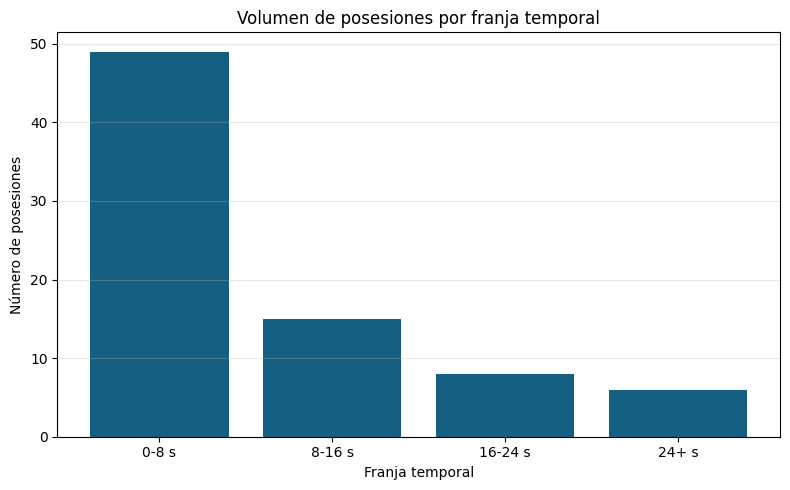

In [ ]:
# Gráfico del volumen de posesiones por franja

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(volumen_franjas.index, volumen_franjas.values, color="#156082")

plt.title("Volumen de posesiones por franja temporal")

plt.xlabel("Franja temporal")

plt.ylabel("Número de posesiones")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(ruta_graficos,"01_volumen_franjas.png"),dpi=300, bbox_inches="tight"
)

plt.show()

**2.2 PPP POR FRANJA TEMPORAL**

¿En qué franja temporal somos más eficientes ofensivamente?

In [ ]:
# Calcular el PPP por franja temporal

ppp_franjas = (
    posesiones_esp
    .groupby("Franja")["Puntos"]
    .mean()
    .reindex(orden_franjas)
)

display(ppp_franjas)

,Puntos
Franja,
0-8 s,0.918367
8-16 s,1.133333
16-24 s,1.250000
24+ s,2.166667


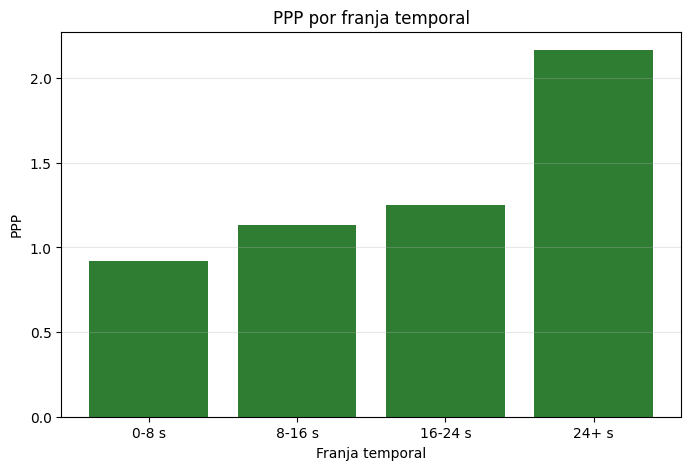

In [ ]:
# Gráfico del PPP por franja temporal

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(ppp_franjas.index, ppp_franjas.values, color="#2E7D32")

plt.title("PPP por franja temporal")

plt.xlabel("Franja temporal")

plt.ylabel("PPP")

plt.grid(axis="y", alpha=0.3)

plt.savefig(
    os.path.join(ruta_graficos,"02_ppp_franjas.png"),dpi=300, bbox_inches="tight"
)

plt.show()

**2.3 PORCENTAJE DE EXITO POR FRANJA**

¿En qué franja temporal finalizamos con éxito un mayor porcentaje de posesiones?

In [ ]:
# Crear variable de éxito

posesiones_esp["Exito"] = posesiones_esp["Puntos"] > 0

In [ ]:
# Calcular el porcentaje de éxito por franja

exito_franjas = (
    posesiones_esp
    .groupby("Franja")["Exito"]
    .mean()
    .mul(100)
    .reindex(orden_franjas)
)

display(exito_franjas)

,Exito
Franja,
0-8 s,42.857143
8-16 s,46.666667
16-24 s,50.000000
24+ s,66.666667


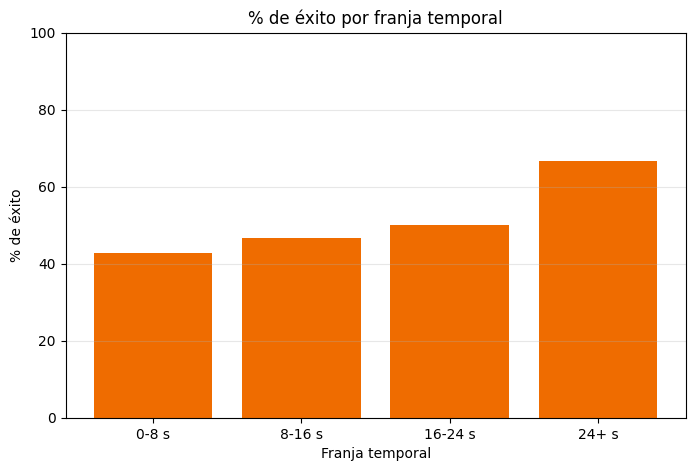

In [ ]:
# Gráfico del porcentaje de éxito por franja

plt.figure(figsize=(8,5))

plt.bar(exito_franjas.index, exito_franjas.values, color="#EF6C00")

plt.title("% de éxito por franja temporal")

plt.xlabel("Franja temporal")

plt.ylabel("% de éxito")

plt.ylim(0, 100)

plt.grid(axis="y", alpha=0.3)

plt.savefig(
    os.path.join(ruta_graficos,"03_exito_franjas.png"),dpi=300, bbox_inches="tight"
)

plt.show()

Aquí se considera una posesión como exitosa cuando termina con al menos un punto.

**2.4TABLA RESUMEN**

In [ ]:
# Tabla resumen por franja temporal

tabla_resumen = posesiones_esp.groupby("Franja").agg(
    Posesiones=("Posesion", "count"),
    PPP=("Puntos", "mean"),
    Exito=("Exito", "mean")
)

tabla_resumen["PPP"] = tabla_resumen["PPP"].round(2)
tabla_resumen["Exito"] = (tabla_resumen["Exito"] * 100).round(0).astype(int)

tabla_resumen = tabla_resumen.rename(columns={
    "Exito": "% éxito"
})

tabla_resumen= tabla_resumen.reindex(["0-8 s","8-16 s", "16-24 s", "24+ s"])

display(tabla_resumen)


,Posesiones,PPP,% éxito
Franja,,,
0-8 s,49,0.92,43
8-16 s,15,1.13,47
16-24 s,8,1.25,50
24+ s,6,2.17,67


**BLOQUE 2. ANALISIS COMBINADO DEL RENDIMIENTO OFENSIVO**

**2.5 VOLUMEN DE POSESIONES POR CUARTO X FRANJA TEMPORAL**

¿En qué momento del partido y en qué franja temporal concentra el equipo la mayor parte de sus posesiones ofensivas?

Se analiza la distribución del volumen de posesiones ofensivas según el cuarto de juego y la franja temporal de finalización, con el objetivo de identificar patrones en el ritmo ofensivo a lo largo del partido.



In [ ]:
# Tabla de volumen de posesiones por cuarto y franja temporal

volumen_cuarto_franja = pd.crosstab(
    posesiones_esp["Cuarto"],
    posesiones_esp["Franja"]
)

# Ordenar las franjas
volumen_cuarto_franja = volumen_cuarto_franja.reindex(
    columns=orden_franjas,
    fill_value=0
)

display(volumen_cuarto_franja)

Franja,0-8 s,8-16 s,16-24 s,24+ s
Cuarto,,,,
Q1,16,6,1,1
Q2,12,2,2,2
Q3,7,3,5,2
Q4,14,4,0,1


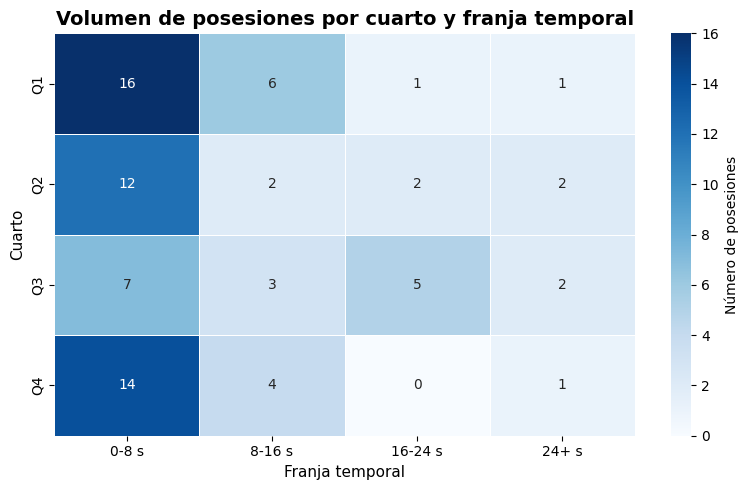

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.heatmap(
    volumen_cuarto_franja,
    annot=True, # Mostrar los valores
    fmt="d", # Números enteros
    cmap="Blues", # Paleta de colores
    linewidths=0.5,
    linecolor="white",
    vmin=0, # La escala empieza en 0
    vmax=volumen_cuarto_franja.values.max(),
    cbar_kws={"label": "Número de posesiones"}
)

plt.title("Volumen de posesiones por cuarto y franja temporal", fontsize=14, weight="bold")
plt.xlabel("Franja temporal", fontsize=11)
plt.ylabel("Cuarto", fontsize=11)

plt.tight_layout()

plt.savefig(
    os.path.join(ruta_graficos, "04_heatmap_volumen.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**2.6 PPP POR CUARTO X FRANJA TEMPORAL**

¿En qué cuarto y en qué franja temporal es más eficiente ofensivamente el equipo?

In [ ]:
# PPP por cuarto y franja temporal

ppp_cuarto_franja = (
    posesiones_esp
    .groupby(["Cuarto", "Franja"])["Puntos"]
    .mean()
    .unstack()
)

# Mantener las franjas en el orden correcto
ppp_cuarto_franja = ppp_cuarto_franja.reindex(
    columns=orden_franjas
)

display(ppp_cuarto_franja.round(2))

Franja,0-8 s,8-16 s,16-24 s,24+ s
Cuarto,,,,
Q1,1.00,0.83,0.0,4.0
Q2,1.42,2.00,1.0,2.5
Q3,0.71,1.33,1.6,2.0
Q4,0.50,1.00,NaN,0.0


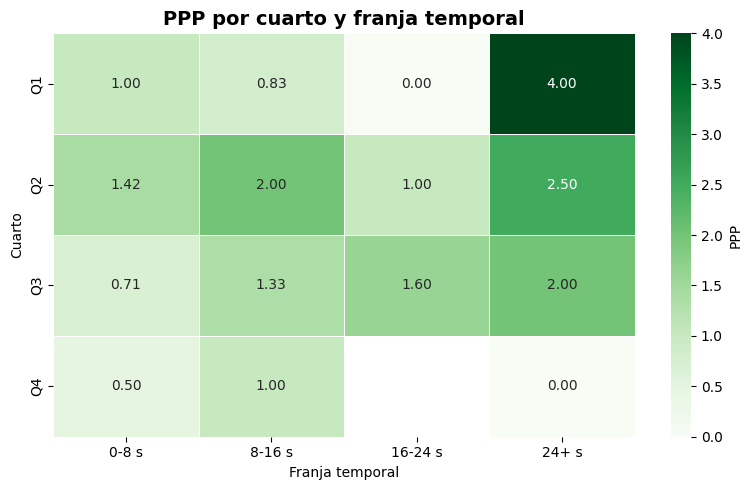

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.heatmap(
    ppp_cuarto_franja,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    linewidths=0.5,
    linecolor="white",
    vmin=0,
    cbar_kws={"label": "PPP"}
)

plt.title(
    "PPP por cuarto y franja temporal",
    fontsize=14,
    weight="bold"
)

plt.xlabel("Franja temporal")
plt.ylabel("Cuarto")

plt.tight_layout()

plt.savefig(
    os.path.join(ruta_graficos, "05_heatmap_ppp.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**2.7 %  DE EXITO POR CUARTO X FRANJA**

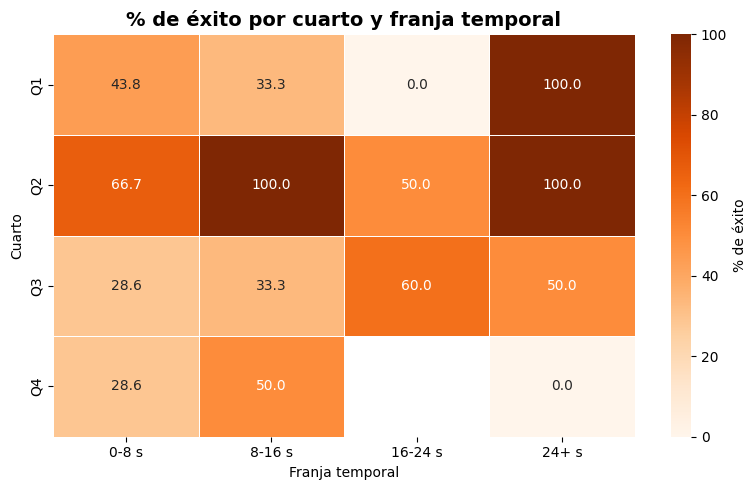

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# % de éxito por cuarto y franja
tabla = (
    posesiones_esp
    .groupby(["Cuarto", "Franja"])["Exito"]
    .mean()
    .unstack() * 100
)

# Ordenar filas y columnas
tabla = tabla.reindex(["Q1", "Q2", "Q3", "Q4"])
tabla = tabla[["0-8 s", "8-16 s", "16-24 s", "24+ s"]]

plt.figure(figsize=(8,5))

sns.heatmap(
    tabla,
    annot=True,
    fmt=".1f",
    cmap="Oranges",
    linewidths=0.5,
    cbar_kws={"label": "% de éxito"}
)

plt.title("% de éxito por cuarto y franja temporal", fontsize=14, fontweight="bold")
plt.xlabel("Franja temporal")
plt.ylabel("Cuarto")

plt.tight_layout()

plt.savefig(
    os.path.join(ruta_graficos, "06_heatmap_exito.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**BLOQUE 3 : ¿ CÓMO EVOLUCIONA EL ATAQUE DURANTE EL PARTIDO?**

**3.1 TABLA RESUMEN DEL PARTIDO (HEATMAP)**

¿En qué cuarto jugamos más?

Dónde somos más eficientes?

Dónde convertimos más posesiones?

En qué cuarto atacamos más rápido o más lento?



In [ ]:
# Tabla resumen por cuarto

tabla_resumen_cuartos = pd.DataFrame({

    "Posesiones": posesiones_esp.groupby("Cuarto")["Posesion"].count(),

    "PPP": posesiones_esp.groupby("Cuarto")["Puntos"].mean(),

    "% éxito": posesiones_esp.groupby("Cuarto")["Exito"].mean() * 100,

    "Duración media (s)": posesiones_esp.groupby("Cuarto")["Duracion"].mean()

}).round({
    "PPP": 2,
    "% éxito": 1,
    "Duración media (s)": 1
})

display(tabla_resumen_cuartos)

,Posesiones,PPP,% éxito,Duración media (s)
Cuarto,,,,
Q1,24,1.04,41.7,6.1
Q2,18,1.56,72.2,7.0
Q3,17,1.24,41.2,13.2
Q4,19,0.58,31.6,5.1


In [ ]:
# Transponer la tabla para que las métricas sean las filas

tabla_heatmap = tabla_resumen_cuartos.T

display(tabla_heatmap)

Cuarto,Q1,Q2,Q3,Q4
Posesiones,24.00,18.00,17.00,19.00
PPP,1.04,1.56,1.24,0.58
% éxito,41.70,72.20,41.20,31.60
Duración media (s),6.10,7.00,13.20,5.10


TABLA SEMÁFORO

esto va a ser muy util para los compañeros que analicen el video

tabla semaforo -> ver el partido de un vistazo

necesito una forma rapida de detectar en qué cuartos se ha funcionado mejor o peor y donde

comparo los valores dentro de cada metrica, y los ordeno con rank -> asigno color

verde: mejor resultado

amarillo y naranja: valores intermedios

rojo -> peor


ojo!! excepcion IMPORTANTEEEE! no siempre más = mejor . sobretodo en basket


puedo preguntarme ⁉
en que cuarto fuimos más eficientes?

mejor PPP con nuestro mayor volumen?

hay algun cuarto donde varias metricas empeoren???

In [ ]:
# Colores de la tabla semáforo

colores = {
    "verde": "#70AD47",
    "amarillo": "#FFD23F",
    "naranja": "#F7941D",
    "rojo": "#F44336"
}

def colorear_fila(fila):
    # Ordenar los valores de menor a mayor
    posiciones = fila.rank(method="first")

    estilos = []

    for columna, valor in fila.items():
        posicion = posiciones[columna]

        # En duración, menor valor = mejor
        if fila.name == "Duración media (s)":
            if posicion == 1:
                color = colores["verde"]
            elif posicion == 2:
                color = colores["amarillo"]
            elif posicion == 3:
                color = colores["naranja"]
            else:
                color = colores["rojo"]

        # En el resto, mayor valor = mejor
        else:
            if posicion == 4:
                color = colores["verde"]
            elif posicion == 3:
                color = colores["amarillo"]
            elif posicion == 2:
                color = colores["naranja"]
            else:
                color = colores["rojo"]

        estilos.append(
            f"background-color: {color}; "
            f"color: black; "
            f"font-weight: bold; "
            f"text-align: center;"
        )

    return estilos


tabla_semaforo = (
    tabla_heatmap.style
    .apply(colorear_fila, axis=1)
    .format({
        "Q1": "{:.2f}",
        "Q2": "{:.2f}",
        "Q3": "{:.2f}",
        "Q4": "{:.2f}"
    })
    .set_caption("Resumen ofensivo por cuarto")
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "18px"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("margin-bottom", "10px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px"),
                ("border", "1px solid white")
            ]
        }
    ])
)

display(tabla_semaforo)

Cuarto,Q1,Q2,Q3,Q4
Posesiones,24.00,18.00,17.00,19.00
PPP,1.04,1.56,1.24,0.58
% éxito,41.70,72.20,41.20,31.60
Duración media (s),6.10,7.00,13.20,5.10


LEYENDA:  

verde= valor más favorable o más alto dentro del indicador.

rojo= valor menos favorable

En la fila de "posesiones" , los colores representan únicamente mayor o menor volumen

**BLOQUE 4: PERFIL OFENSIVO DEL EQUIPO**

A partir de las métricas obtenidas en los bloques anteriores, se genera automáticamente un perfil ofensivo del equipo que resume las principales características de su comportamiento durante el partido.

-> dejo de mirar solo las posesiones individuales y construyo el estilo ofensivo de españa

que ritmo de ataque utiliza el equipo y con qué ritmo obtiene mayor rendimiento ??

las posesiones se van a dividir en 3 grupos 🇰

las rapidas <= 8 s , las medias 9-16 s , largas > 16 s


el volumen me dice como juega el equipo , el ppp me dice como de eficiente resulta ese ritmo

In [ ]:
# Clasificar las posesiones según su duración

def clasificar_duracion(seg):
    if seg <= 8:
        return "Posesiones rápidas"
    elif seg <= 16:
        return "Posesiones medias"
    else:
        return "Posesiones largas"

posesiones_esp["Perfil"] = posesiones_esp["Duracion"].apply(clasificar_duracion)

In [ ]:
# Resumen del perfil ofensivo

perfil = posesiones_esp.groupby("Perfil").agg(
    Posesiones=("Posesion","count"),
    PPP=("Puntos","mean")
)

display(perfil)

,Posesiones,PPP
Perfil,,
Posesiones largas,14,1.642857
Posesiones medias,15,1.133333
Posesiones rápidas,49,0.918367


In [ ]:
# PERFIL OFENSIVO VISUAL
# ============================

volumen = perfil["Posesiones"]
ppp = perfil["PPP"]

max_cuadrados = 12

def barra(valor, maximo):
    n = round(valor/maximo*max_cuadrados)
    if valor > 0:
        n = max(1, n)
    return "■"*n

print("PERFIL OFENSIVO DEL EQUIPO")
print("="*45)

print("\nVolumen de posesiones")
for nombre, valor in volumen.items():
    print(f"{nombre:<22} {barra(valor, volumen.max())} {int(valor)}")

print("\nPPP")
for nombre, valor in ppp.items():
    print(f"{nombre:<22} {barra(valor, ppp.max())} {valor:.2f}")

PERFIL OFENSIVO DEL EQUIPO

Volumen de posesiones
Posesiones largas      ■■■ 14
Posesiones medias      ■■■■ 15
Posesiones rápidas     ■■■■■■■■■■■■ 49

PPP
Posesiones largas      ■■■■■■■■■■■■ 1.64
Posesiones medias      ■■■■■■■■ 1.13
Posesiones rápidas     ■■■■■■■ 0.92


Interpretación: la parte superior muestra cómo juega el equipo (volumen) y la inferior qué tipo de ataque le da mejores resultados (PPP).

Comparando ambas se identifica el perfil ofensivo y posibles oportunidades de mejora.

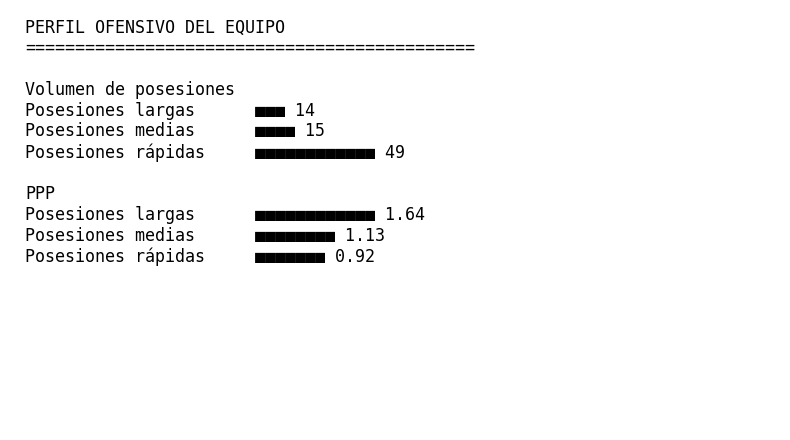

In [ ]:
# GUARDAR PERFIL OFENSIVO COMO IMAGEN
# ==========================================

lineas = []

lineas.append("PERFIL OFENSIVO DEL EQUIPO")
lineas.append("=" * 45)
lineas.append("")
lineas.append("Volumen de posesiones")

for nombre, valor in volumen.items():
    lineas.append(
        f"{nombre:<22} {barra(valor, volumen.max())} {int(valor)}"
    )

lineas.append("")
lineas.append("PPP")

for nombre, valor in ppp.items():
    lineas.append(
        f"{nombre:<22} {barra(valor, ppp.max())} {valor:.2f}"
    )

texto_perfil = "\n".join(lineas)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axis("off")

ax.text(
    0.02,
    0.98,
    texto_perfil,
    va="top",
    ha="left",
    fontsize=12,
    family="monospace"
)

plt.tight_layout()

plt.savefig(
    os.path.join(ruta_graficos, "07_perfil_ofensivo.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**BLOQUE 5 ORIGEN DE LA ANOTACIÓN**

ahora quiero saber de donde procede esa anotacion

primero debo inspeccionar la columna de action  -> cómo funciona fiba con cada accion ??

como se generan los puntos de españa? empiezo identificando las principales fuentes de produccion ofensiva. a partir del pbp  voy a estudiar las canastas , asistencias y diferentes contextos de anotacion -> contraataque , los puntos tras perdida rival y las segundas oportunidades.

objetivo: entender qué situaciones ofensivas producen los puntos que se anotan cada equipo y qué mecanismos tienen mayor peso en el ataque

In [ ]:
print(df["AC"].value_counts().sort_index())

AC
ASS        33
BS          1
CFOUL       1
ENDG        1
ENDP        4
FOUL       35
FT         39
JB          2
JS          5
P2         76
P3         42
REB        73
RFOUL      35
ST         32
STARTG      1
STARTP      4
SUBST     130
TIMO        3
TO         47
TREB        7
TTO         2
Name: count, dtype: int64


In [ ]:
acciones = (
    df[["AC", "Action"]]
    .drop_duplicates()
    .sort_values("AC")
)

display(acciones)

,AC,Action
12,ASS,made the assist
557,BS,blocked the shot
60,CFOUL,Technical foul coach
572,ENDG,End of game
150,ENDP,End of period
...,...,...
38,TO,turnover; ball handling
17,TO,turnover; bad pass
192,TREB,team offensive rebound
94,TREB,team defensive rebound


In [ ]:
acciones[
    acciones["AC"].isin(["P2", "P3", "FT", "REB", "ST", "ASS"])
]

,AC,Action
12,ASS,made the assist
225,FT,1st of 2 free throws missed
125,FT,2nd of 2 free throws missed
32,FT,Free throw made 2 of 2
31,FT,Free throw made 1 of 2
24,FT,2nd of 2 free throws made
23,FT,1st of 2 free throws made
61,FT,1st free throw missed
19,P2,"2PtsFG under the basket, points after turnover..."
104,P2,"2PtsFG inside right, jump shot missed"


puntos por contraataque (fastbreak)

puntos tras pérdida rival (points after turnover)

puntos de segunda oportunidad (points from second chance)

Veo el origen de la anotación

In [ ]:
# Acciones del equipo analizado
acciones_equipo = df[df["T1"] == equipo_esp].copy()

# Canastas asistidas
canastas_asistidas = (acciones_equipo["AC"] == "ASS").sum()

print("Canastas asistidas:", canastas_asistidas)

Canastas asistidas: 27


Total de canastas anotadas

In [ ]:
# Canastas de 2 y 3 anotadas
canastas_anotadas = (
    acciones_equipo["AC"].isin(["P2", "P3"])
    & acciones_equipo["Action"].str.contains("made", case=False, na=False)
).sum()

print("Canastas anotadas:", canastas_anotadas)

Canastas anotadas: 32


Porcentaje %

In [ ]:
porcentaje_asistidas = (
    canastas_asistidas / canastas_anotadas * 100
    if canastas_anotadas > 0
    else 0
)

print(f"% de canastas asistidas: {porcentaje_asistidas:.1f}%")

% de canastas asistidas: 84.4%


% de canastas sin asistencia

In [ ]:
canastas_sin_asistencia = canastas_anotadas - canastas_asistidas

porcentaje_sin_asistencia = (
    canastas_sin_asistencia / canastas_anotadas * 100
    if canastas_anotadas > 0
    else 0
)

print("Canastas sin asistencia:", canastas_sin_asistencia)
print(f"% de canastas sin asistencia: {porcentaje_sin_asistencia:.1f}%")

Canastas sin asistencia: 5
% de canastas sin asistencia: 15.6%


PUNTOS TRAS ROBO

1 buscar todos los robos (ST) de España en (T1== equipo_esp)

2 localizar la posesion siguiente

3 comprobar cuántos puntos se anotan en cada posesion

In [ ]:
# PUNTOS OBTENIDOS DESPUÉS DE UN ROBO
# =====================================================

# Robos realizados por el equipo analizado
robos_equipo = df[
    (df["T1"] == equipo_esp) &
    (df["AC"] == "ST")
][["Quarter", "Time", "Posesion"]].copy()

resultados_robos = []

for _, robo in robos_equipo.iterrows():

    # Buscar la primera posesión posterior del equipo en el mismo cuarto
    posesiones_posteriores = posesiones[
        (posesiones["Equipo"] == equipo_esp) &
        (posesiones["Cuarto"] == robo["Quarter"]) &
        (posesiones["Posesion"] > robo["Posesion"])
    ].sort_values("Posesion")

    if not posesiones_posteriores.empty:
        siguiente_posesion = posesiones_posteriores.iloc[0]

        resultados_robos.append({
            "Cuarto": robo["Quarter"],
            "Momento del robo": robo["Time"],
            "Posesión posterior": siguiente_posesion["Posesion"],
            "Puntos obtenidos": siguiente_posesion["Puntos"]
        })

tabla_tras_robo = pd.DataFrame(resultados_robos)

display(tabla_tras_robo)

,Cuarto,Momento del robo,Posesión posterior,Puntos obtenidos
0,Q1,8:43,5,2
1,Q1,7:22,13,2
2,Q1,5:20,17,2
3,Q1,4:48,19,2
4,Q1,4:17,21,2
5,Q1,3:51,23,0
6,Q1,0:04,39,3
7,Q2,9:43,42,0
8,Q2,9:28,44,0
9,Q2,6:41,54,2


quiero ver un resumen

Robos realizados

Robos con posesión posterior analizada

Puntos obtenidos tras robo

Robos que terminaron con puntos

% de robos aprovechados

Puntos por robo

In [ ]:
# Resumen de eficacia después de robo

numero_robos = len(robos_equipo)
robos_analizados = len(tabla_tras_robo)
puntos_tras_robo = tabla_tras_robo["Puntos obtenidos"].sum()

robos_con_puntos = (
    tabla_tras_robo["Puntos obtenidos"] > 0
).sum()

porcentaje_robos_con_puntos = (
    robos_con_puntos / robos_analizados * 100
    if robos_analizados > 0
    else 0
)

puntos_por_robo = (
    puntos_tras_robo / robos_analizados
    if robos_analizados > 0
    else 0
)

print("Robos realizados:", numero_robos)
print("Robos con posesión posterior analizada:", robos_analizados)
print("Puntos obtenidos tras robo:", puntos_tras_robo)
print("Robos que terminaron con puntos:", robos_con_puntos)
print(f"% de robos aprovechados: {porcentaje_robos_con_puntos:.1f}%")
print(f"Puntos por robo: {puntos_por_robo:.2f}")

Robos realizados: 21
Robos con posesión posterior analizada: 21
Puntos obtenidos tras robo: 31
Robos que terminaron con puntos: 14
% de robos aprovechados: 66.7%
Puntos por robo: 1.48


INTERPRETACIÓN

puntos tras robo: producción total obtenida en las posesiones posteriores a una recuperación

% de robos aprovechados: porcentaje de recuperaciones que acabaron con al menos un punto

puntos por robo: rendimiento medio generado por cada recuperación analizada

PUNTOS TRAS REBOTE OFENSIVO

quiero ver la capacidad que tiene españa para transformar los rebotes ofensivos en anotacion -> aprovechar las segundas oportunidades generadas durante el ataque


primero identifico los rebotes ofensivos de españa y luego busco la continuacion ofensiva correspondiente para comprobar si hay o no segunda oportunidad y si termina produciendo puntos.


con interrows -> recorro cada rebote ofensivo individualmente

busco la posesion posterior de españa, dentro del mismo cuarto y luego se queda con la primera que se encuentra


ojo! un rebote ofensivo normalmente no inicia una nueva posesion , prolonga la misma posesion ofensiva

In [ ]:
# PUNTOS OBTENIDOS DESPUÉS DE REBOTE OFENSIVO
# =====================================================

# Rebotes ofensivos del equipo analizado
rebotes_ofensivos = df[
    (df["T1"] == equipo_esp) &
    (df["AC"] == "REB") &
    (df["Action"].str.contains("offensive rebound", case=False, na=False))
][["Quarter", "Time", "Posesion"]].copy()

resultados_rebote_ofensivo = []

for _, rebote in rebotes_ofensivos.iterrows():

    # Buscar la primera posesión posterior del equipo en el mismo cuarto
    posesiones_posteriores = posesiones[
        (posesiones["Equipo"] == equipo_esp) &
        (posesiones["Cuarto"] == rebote["Quarter"]) &
        (posesiones["Posesion"] > rebote["Posesion"])
    ].sort_values("Posesion")

    if not posesiones_posteriores.empty:
        siguiente_posesion = posesiones_posteriores.iloc[0]

        resultados_rebote_ofensivo.append({
            "Cuarto": rebote["Quarter"],
            "Momento del rebote": rebote["Time"],
            "Posesión posterior": siguiente_posesion["Posesion"],
            "Puntos obtenidos": siguiente_posesion["Puntos"]
        })

tabla_tras_rebote_ofensivo = pd.DataFrame(
    resultados_rebote_ofensivo
)

display(tabla_tras_rebote_ofensivo)

,Cuarto,Momento del rebote,Posesión posterior,Puntos obtenidos
0,Q1,9:52,2,3
1,Q1,8:38,6,0
2,Q1,7:58,9,0
3,Q1,3:12,27,0
4,Q1,0:42,37,0
5,Q1,0:12,39,3
6,Q1,0:10,39,3
7,Q2,2:31,68,1
8,Q2,1:42,71,2
9,Q3,8:21,80,0


In [ ]:
# RESUMEN TRAS REBOTE OFENSIVO
# =====================================================

numero_rebotes_ofensivos = len(rebotes_ofensivos)
rebotes_analizados = len(tabla_tras_rebote_ofensivo)

puntos_tras_rebote_ofensivo = (
    tabla_tras_rebote_ofensivo["Puntos obtenidos"].sum()
)

rebotes_con_puntos = (
    tabla_tras_rebote_ofensivo["Puntos obtenidos"] > 0
).sum()

porcentaje_rebotes_con_puntos = (
    rebotes_con_puntos / rebotes_analizados * 100
    if rebotes_analizados > 0
    else 0
)

puntos_por_rebote_ofensivo = (
    puntos_tras_rebote_ofensivo / rebotes_analizados
    if rebotes_analizados > 0
    else 0
)

print("Rebotes ofensivos:", numero_rebotes_ofensivos)
print("Rebotes con posesión posterior analizada:", rebotes_analizados)
print("Puntos obtenidos tras rebote ofensivo:",
      puntos_tras_rebote_ofensivo)
print("Rebotes ofensivos que terminaron con puntos:",
      rebotes_con_puntos)
print(
    f"% de rebotes ofensivos aprovechados: "
    f"{porcentaje_rebotes_con_puntos:.1f}%"
)
print(
    f"Puntos por rebote ofensivo: "
    f"{puntos_por_rebote_ofensivo:.2f}"
)

Rebotes ofensivos: 28
Rebotes con posesión posterior analizada: 24
Puntos obtenidos tras rebote ofensivo: 28
Rebotes ofensivos que terminaron con puntos: 10
% de rebotes ofensivos aprovechados: 41.7%
Puntos por rebote ofensivo: 1.17


PUNTOS EN TRANSICIÓN (CONTRAATAQUE)

ahora identifico la anotacion obtenida por españa en situaciones de transicion o contraataque -> tengo que usar las etiquetas del pbp fast break y points from fastbreak

objetivo: cuantificar cuanto contribuye el juego en transicion a la produccion ofensiva y comprobar si el equipo consigue transformar situaciones rapidas en puntos


primero exijo a t1 == equipo espa y despues bussco expresiones en action y si conserva putnos_action

In [ ]:
# PUNTOS EN TRANSICIÓN (FASTBREAK)
# =====================================================

transicion = df[
    (df["T1"] == equipo_esp) &
    (
        df["Action"].str.contains("fast break", case=False, na=False) |
        df["Action"].str.contains("points from fastbreak", case=False, na=False)
    )
][["Quarter", "Time", "AC", "Action", "Puntos_Accion"]].copy()

display(transicion)

,Quarter,Time,AC,Action,Puntos_Accion
77,Q1,4:44,P2,"2PtsFG inside paint, points from fastbreak + a...",2
88,Q1,4:14,P2,"2PtsFG inside paint, points from fastbreak + a...",2
148,Q1,0:00,P3,"3PtsFG outside left, points from fastbreak + a...",3
199,Q2,6:37,P2,"2PtsFG under the basket, points from fastbreak...",2
217,Q2,4:53,P2,"2PtsFG inside paint, points from fastbreak + a...",2
289,Q3,9:32,P2,"2PtsFG under the basket, fast break, layup made",2


In [ ]:
numero_canastas_transicion = len(transicion)

puntos_transicion = transicion["Puntos_Accion"].sum()

print("Canastas en transición:", numero_canastas_transicion)
print("Puntos en transición:", puntos_transicion)
print(f"Puntos por canasta en transición: {puntos_transicion/numero_canastas_transicion:.2f}")

Canastas en transición: 6
Puntos en transición: 13
Puntos por canasta en transición: 2.17


**TABLA RESUMEN : ORIGEN DE LA ANOTACIÓN**

In [ ]:
# TABLA VISUAL: ORIGEN DE LA ANOTACIÓN
# =====================================================

tabla_origen_anotacion = pd.DataFrame({
    "Indicador": [
        "Canastas asistidas",
        "Canastas sin asistencia",
        "Puntos tras robo",
        "% robos aprovechados",
        "PPP tras robo",
        "Puntos tras rebote ofensivo",
        "% rebotes ofensivos aprovechados",
        "PPP tras rebote ofensivo",
        "Canastas en transición",
        "Puntos en transición"
    ],
    "Valor": [
        f"{canastas_asistidas} ({porcentaje_asistidas:.1f}%)",
        f"{canastas_sin_asistencia} ({porcentaje_sin_asistencia:.1f}%)",
        f"{puntos_tras_robo:.0f}",
        f"{porcentaje_robos_con_puntos:.1f}%",
        f"{puntos_por_robo:.2f}",
        f"{puntos_tras_rebote_ofensivo:.0f}",
        f"{porcentaje_rebotes_con_puntos:.1f}%",
        f"{puntos_por_rebote_ofensivo:.2f}",
        f"{numero_canastas_transicion}",
        f"{puntos_transicion:.0f}"
    ]
})

display(tabla_origen_anotacion)

,Indicador,Valor
0,Canastas asistidas,27 (84.4%)
1,Canastas sin asistencia,5 (15.6%)
2,Puntos tras robo,31
3,% robos aprovechados,66.7%
4,PPP tras robo,1.48
5,Puntos tras rebote ofensivo,28
6,% rebotes ofensivos aprovechados,41.7%
7,PPP tras rebote ofensivo,1.17
8,Canastas en transición,6
9,Puntos en transición,13


AÑADO COLOR PARA EL FORMATO

In [ ]:
verde = "#70AD47"
amarillo = "#FFD23F"
naranja = "#F7941D"
rojo = "#F44336"

def color_indicador(fila):
    indicador = fila["Indicador"]

    if indicador == "Canastas asistidas":
        valor = porcentaje_asistidas
        if valor >= 60:
            color = verde
        elif valor >= 40:
            color = amarillo
        else:
            color = rojo

    elif indicador == "% robos aprovechados":
        valor = porcentaje_robos_con_puntos
        if valor >= 50:
            color = verde
        elif valor >= 30:
            color = amarillo
        else:
            color = rojo

    elif indicador == "PPP tras robo":
        valor = puntos_por_robo
        if valor >= 1.10:
            color = verde
        elif valor >= 0.80:
            color = amarillo
        else:
            color = rojo

    elif indicador == "% rebotes ofensivos aprovechados":
        valor = porcentaje_rebotes_con_puntos
        if valor >= 45:
            color = verde
        elif valor >= 30:
            color = amarillo
        else:
            color = rojo

    elif indicador == "PPP tras rebote ofensivo":
        valor = puntos_por_rebote_ofensivo
        if valor >= 1.00:
            color = verde
        elif valor >= 0.70:
            color = amarillo
        else:
            color = rojo

    else:
        color = "#F2F2F2"

    return [
        "background-color: white",
        f"background-color: {color}; font-weight: bold; text-align: center"
    ]

In [ ]:
tabla_origen_visual = (
    tabla_origen_anotacion.style
    .apply(color_indicador, axis=1)
    .set_caption("Origen de la anotación")
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "18px"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("margin-bottom", "10px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("background-color", "#EDEDED")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "8px"),
                ("border", "1px solid white")
            ]
        }
    ])
)

display(tabla_origen_visual)

,Indicador,Valor
0,Canastas asistidas,27 (84.4%)
1,Canastas sin asistencia,5 (15.6%)
2,Puntos tras robo,31
3,% robos aprovechados,66.7%
4,PPP tras robo,1.48
5,Puntos tras rebote ofensivo,28
6,% rebotes ofensivos aprovechados,41.7%
7,PPP tras rebote ofensivo,1.17
8,Canastas en transición,6
9,Puntos en transición,13


**BLOQUE 6: ORIGEN DE LAS PERDIDAS**

tengo que identificar las perdidas cometidas por españa y clasifico segun su origen a partir de la informacion del pbp

voy a distinguir entre diferentes causas: mal pase, pérdida de bote/ manejo de balón, pasos u otras pérdidas no especificadas.

-> calculo el porcentaje que representa cada tipo sobre el total de perdidas -> detecto las situaciones que generan una mayor perdida de dposesiones y posibles aspectos de mejora ofensiva.

ojo! actionOris contiene la descripcion original de la perdida

value_counts() cuenta cuántas veces aparece cada tipo -> frecuencia


frecuencia / total x 100 -> qué porcentaje representa cada tipo de perdida

objetivo: pasar de decir " espña  perdió X balones " a decir " la principal causa de perdida fueron los malos pases"

In [ ]:
perdidas_equipo = df[
    (df["T1"] == equipo_esp) &
    (df["AC"] == "TO")
][["Quarter", "Time", "Action", "ActionOris"]].copy()

display(perdidas_equipo)


,Quarter,Time,Action,ActionOris
27,Q1,8:20,turnover; bad pass,"Turnover, bad pass"
38,Q1,7:31,turnover; ball handling,"Turnover, ball handling"
68,Q1,5:38,turnover; bad pass,"Turnover, bad pass"
108,Q1,2:06,turnover; ball handling,"Turnover, ball handling"
133,Q1,0:39,turnover; bad pass,"Turnover, bad pass"
156,Q2,9:38,turnover; bad pass,"Turnover, bad pass"
171,Q2,8:20,turnover; bad pass,"Turnover, bad pass"
237,Q2,2:54,turnover; out of bounds,"Turnover, out of bounds"
303,Q3,8:20,turnover; bad pass,"Turnover, bad pass"
381,Q3,4:29,turnover; ball handling,"Turnover, ball handling"


Turnover, bad pass: mal pase

turnover, ball handling: mal manejo/pérdida de bote

turnover, travelling violation: pasos

turnover: sin especificar

In [ ]:
# Resumen del origen de las pérdidas

tabla_perdidas = (
    perdidas_equipo["ActionOris"]
    .value_counts()
    .reset_index()
)

tabla_perdidas.columns = ["Tipo de pérdida", "Frecuencia"]

tabla_perdidas["%"] = (
    tabla_perdidas["Frecuencia"] /
    tabla_perdidas["Frecuencia"].sum() * 100
).round(1)

display(tabla_perdidas)

,Tipo de pérdida,Frecuencia,%
0,"Turnover, bad pass",13,68.4
1,"Turnover, ball handling",4,21.1
2,"Turnover, out of bounds",2,10.5


IMPORTANTEEEEEEEEE!!!!!!!!!!! ANTES DE HACER WORD SUBIR LOS DOS GRAFICOS AL DRIVE EL 08 Y 09

**WORD AUTOMÁTICO**

IMPORTANTE!!!! CAMBIAR RIVAL EN CADA PARTIDO!!!

In [ ]:
import os

RIVAL = "M"

nombre_csv = os.path.basename(ruta_csv)
id_partido = os.path.splitext(nombre_csv)[0].replace("pbp_", "")

nombre_partido = f"ESPAÑA VS {RIVAL}"

ruta_informes = "/content/drive/MyDrive/Informes_Baloncesto"
os.makedirs(ruta_informes, exist_ok=True)

ruta_word = os.path.join(
    ruta_informes,
    f"Informe_{id_partido}_ESP_vs_{RIVAL}.docx"
)

#ruta logo
ruta_logo=os.path.join(ruta_informes,"Logo.png")

CREAR EL DOCUMENTO

In [ ]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION
from docx.enum.table import WD_TABLE_ALIGNMENT

doc = Document()

# Márgenes
seccion = doc.sections[0]
seccion.top_margin = Inches(0.4)
seccion.bottom_margin = Inches(0.4)
seccion.left_margin = Inches(0.5)
seccion.right_margin = Inches(0.5)

# Fuente por defecto
estilo = doc.styles["Normal"]
estilo.font.name = "Arial"
estilo.font.size = Pt(9)

print("Documento creado correctamente.")

Documento creado correctamente.


FUNCION PARA LA CABECERA WORD

In [ ]:
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT

def crear_encabezado(doc):

    section = doc.sections[0]
    header = section.header

    # Tabla de dos columnas
    tabla = header.add_table(rows=1, cols=2, width=Inches(6.8))
    tabla.alignment = WD_TABLE_ALIGNMENT.CENTER
    tabla.autofit = False

    # Ancho de columnas
    tabla.columns[0].width = Inches(1.6)
    tabla.columns[1].width = Inches(5.2)

    # Columna izquierda (LOGO)
    # ===========================

    celda_logo = tabla.cell(0,0)

    p_logo = celda_logo.paragraphs[0]
    p_logo.alignment = WD_ALIGN_PARAGRAPH.LEFT

    run = p_logo.add_run()
    run.add_picture(ruta_logo, width=Inches(1.6))

    # Columna derecha (TEXTO)
    # ===========================

    celda_texto = tabla.cell(0,1)

    p = celda_texto.paragraphs[0]

    run = p.add_run("INFORME RÁPIDO OFENSIVO\n")
    run.bold = True
    run.font.size = Pt(16)

    run = p.add_run(f"{nombre_partido}\n")
    run.font.size = Pt(11)

    run = p.add_run(f"Game ID: {id_partido}")
    run.italic = True
    run.font.size = Pt(9)

In [ ]:
crear_encabezado(doc)

doc.save(ruta_word)

print("Word guardado en: ")
print(ruta_word)

Word guardado en: 
/content/drive/MyDrive/Informes_Baloncesto/Informe_131881_ESP_vs_MONTENEGRO.docx


TITULO DE CADA PAGINA

In [ ]:
from docx.shared import Pt, RGBColor

def agregar_titulo(doc, texto):

    p = doc.add_paragraph()

    run = p.add_run(texto)
    run.bold = True
    run.font.size = Pt(14)
    run.font.color.rgb = RGBColor(31, 78, 121) # Azul elegante

    doc.add_paragraph()

In [ ]:
agregar_titulo(doc, "¿Cómo atacamos?")

doc.save(ruta_word)

mini tabla por franjas

In [ ]:
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml import OxmlElement
from docx.oxml.ns import qn


def sombrear_celda(celda, color):
    sombreado = OxmlElement("w:shd")
    sombreado.set(qn("w:fill"), color)
    celda._tc.get_or_add_tcPr().append(sombreado)


# Tabla resumen por franjas
tabla_word = doc.add_table(rows=1, cols=4)
tabla_word.alignment = WD_TABLE_ALIGNMENT.CENTER
tabla_word.style = "Table Grid"

encabezados = ["Franja", "Posesiones", "PPP", "% éxito"]

for i, texto in enumerate(encabezados):
    celda = tabla_word.rows[0].cells[i]
    celda.text = texto
    celda.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER
    sombrear_celda(celda, "1F4E79")

    p = celda.paragraphs[0]
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER

    for run in p.runs:
        run.bold = True
        run.font.size = Pt(8)
        run.font.color.rgb = RGBColor(255, 255, 255)


for franja, fila in tabla_resumen.iterrows():
    celdas = tabla_word.add_row().cells

    valores = [
        franja,
        int(fila["Posesiones"]),
        f'{fila["PPP"]:.2f}',
        f'{fila["% éxito"]:.0f}%'
    ]

    for i, valor in enumerate(valores):
        celdas[i].text = str(valor)
        celdas[i].vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER

        p = celdas[i].paragraphs[0]
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER

        for run in p.runs:
            run.font.size = Pt(8)

In [ ]:
doc.save(ruta_word)

3 graficas de barras + perfil ascii

In [ ]:
tabla = doc.add_table(rows=2, cols=2)
tabla.alignment = WD_TABLE_ALIGNMENT.CENTER

imagenes = [
    "01_volumen_franjas.png",
    "02_ppp_franjas.png",
    "03_exito_franjas.png",
    "07_perfil_ofensivo.png"
]

k = 0
for fila in range(2):
    for col in range(2):
        p = tabla.cell(fila, col).paragraphs[0]
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER

        p.add_run().add_picture(
            os.path.join(ruta_graficos, imagenes[k]),
            width=Inches(2.3)
        )

        k += 1

In [ ]:
doc.save(ruta_word)

PAGINA 2

In [ ]:
doc.add_page_break()

agregar_titulo(doc, "¿Cuándo atacamos mejor?")

In [ ]:
doc.save(ruta_word)

In [ ]:
tabla_pagina2 = doc.add_table(rows=2, cols=2)
tabla_pagina2.alignment = WD_TABLE_ALIGNMENT.CENTER
tabla_pagina2.autofit = False

imagenes_pagina2 = [
    ["04_heatmap_volumen.png", "05_heatmap_ppp.png"],
    ["06_heatmap_exito.png", "09_tabla_resumen_ofensivo.png"]
]

for fila in range(2):
    for columna in range(2):

        celda = tabla_pagina2.cell(fila, columna)
        parrafo = celda.paragraphs[0]
        parrafo.alignment = WD_ALIGN_PARAGRAPH.CENTER

        ruta_imagen = os.path.join(
            ruta_graficos,
            imagenes_pagina2[fila][columna]
        )

        parrafo.add_run().add_picture(
            ruta_imagen,
            width=Inches(2.7)
        )

# Guardar el Word actualizado
doc.save(ruta_word)

pagina 3!!! recordar añadir pie de pagina " Analista: Claudia Roncero..."

In [ ]:
doc.add_page_break()

agregar_titulo(doc, "Anotación")

doc.save(ruta_word)

claves automáticas

muy util para el equipo !!!

el codigo va a seleccionar automaticamente algunos de los resultados + representativos .

**conclusiones breves:**

Mayor volumen en 0-8 s:

• Mejor rendimiento en 24+ s:

• % de las canastas fueron asistidas.

• Tras rebote ofensivo:

franja con mayor volumen -> se busca mediante idmax() la franja en la que españa acumuló + posesiones

franja con mejor rendimiento -> localizo la que tenga el ppp mas alto

canastas asistidas -> % que fueron precedidas por asistencia

reobte ofensivo -> puntos x posesion obtenidos tras rebote ofensivo.

In [ ]:
claves_partido = []

# Franja con mayor volumen
franja_mas_usada = tabla_resumen["Posesiones"].idxmax()
posesiones_mas_usada = int(tabla_resumen.loc[franja_mas_usada, "Posesiones"])

claves_partido.append(
    f"Mayor volumen en {franja_mas_usada}: "
    f"{posesiones_mas_usada} posesiones."
)

# Franja con mejor PPP
franja_mejor_ppp = tabla_resumen["PPP"].idxmax()
mejor_ppp = tabla_resumen.loc[franja_mejor_ppp, "PPP"]

claves_partido.append(
    f"Mejor rendimiento en {franja_mejor_ppp}: "
    f"{mejor_ppp:.2f} PPP."
)

# Canastas asistidas
claves_partido.append(
    f"{porcentaje_asistidas:.1f}% de las canastas fueron asistidas."
)

# Rebote ofensivo
claves_partido.append(
    f"Tras rebote ofensivo: "
    f"{puntos_por_rebote_ofensivo:.2f} puntos por posesión."
)

for clave in claves_partido:
    print("•", clave)


• Mayor volumen en 0-8 s: 49 posesiones.
• Mejor rendimiento en 24+ s: 2.17 PPP.
• 84.4% de las canastas fueron asistidas.
• Tras rebote ofensivo: 1.17 puntos por posesión.


In [ ]:
tabla_pagina3 = doc.add_table(rows=1, cols=2)
tabla_pagina3.alignment = WD_TABLE_ALIGNMENT.CENTER
tabla_pagina3.autofit = False

# ----- Tabla origen de la anotación -----
p = tabla_pagina3.cell(0, 0).paragraphs[0]
p.alignment = WD_ALIGN_PARAGRAPH.CENTER

p.add_run().add_picture(
    os.path.join(ruta_graficos, "08_tabla_origen_anotacion.png"),
    width=Inches(2.9)
)

# ----- Claves del partido -----
p = tabla_pagina3.cell(0, 1).paragraphs[0]

run = p.add_run("CLAVES DEL PARTIDO\n\n")
run.bold = True
run.font.size = Pt(11)

# Aquí irán las frases automáticas
for clave in claves_partido:
  run=p.add_run(f"· {clave}\n\n")
  run.font.size= Pt(9)

doc.save(ruta_word)